# Spotify-Audio-Features-Analysis

## LIBRARIES

In [93]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## DATASET

### Data

In [94]:
df=pd.read_csv('dataset.csv')
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### Data Cleaning

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [96]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [97]:
df.isna().count()

Unnamed: 0          114000
track_id            114000
artists             114000
album_name          114000
track_name          114000
popularity          114000
duration_ms         114000
explicit            114000
danceability        114000
energy              114000
key                 114000
loudness            114000
mode                114000
speechiness         114000
acousticness        114000
instrumentalness    114000
liveness            114000
valence             114000
tempo               114000
time_signature      114000
track_genre         114000
dtype: int64

So No Empty Data or NULL Data

### Selecting Most Famous Genre

In [98]:
df['track_genre'].value_counts()

track_genre
acoustic             1000
punk-rock            1000
progressive-house    1000
power-pop            1000
pop                  1000
                     ... 
folk                 1000
emo                  1000
electronic           1000
electro              1000
world-music          1000
Name: count, Length: 114, dtype: int64

So all genre are equally popular. So we select electro

In [99]:
genre='electro'
df=df[df['track_genre']==genre]
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
31000,31000,7BKLCZ1jbUBVqRi2FVlTVw,The Chainsmokers;Halsey,Closer,Closer,84,244960,False,0.748,0.524,...,-5.599,1,0.0338,0.4140,0.000000,0.1110,0.661,95.010,4,electro
31001,31001,18uwL0vNUanqZH0ro2QcOP,Jeremy Zucker,"summer,",comethru,79,181613,False,0.795,0.178,...,-11.991,1,0.0574,0.6070,0.000000,0.6230,0.608,93.982,4,electro
31002,31002,0lYBSQXN6rCTvUZvg9S0lU,DJ Snake;Justin Bieber,Encore,Let Me Love You,84,205946,False,0.649,0.716,...,-5.371,1,0.0349,0.0863,0.000026,0.1350,0.163,99.988,4,electro
31003,31003,5p7ujcrUXASCNwRaWNHR1C,Halsey,Without Me,Without Me,78,201660,True,0.752,0.488,...,-7.050,1,0.0705,0.2970,0.000009,0.0936,0.533,136.041,4,electro
31004,31004,4IQqOlTZpfjnSTOArpZX5j,Farasat Anees;Slick Trick;Toshi,OFIVE1,BIBA,66,216216,False,0.758,0.573,...,-6.221,0,0.0428,0.0888,0.000677,0.0834,0.284,110.983,4,electro


### Selecting features

In [100]:
features=['danceability','energy','loudness','speechiness','valence']
data=df[features]
data.head()

,danceability,energy,loudness,speechiness,valence
31000,0.748,0.524,-5.599,0.0338,0.661
31001,0.795,0.178,-11.991,0.0574,0.608
31002,0.649,0.716,-5.371,0.0349,0.163
31003,0.752,0.488,-7.050,0.0705,0.533
31004,0.758,0.573,-6.221,0.0428,0.284


### Scale

In [101]:
a=data.to_numpy(dtype=float)
scale=(a-a.min(axis=0))/a.max(axis=0)-a.min(axis=0)
scaledf=pd.DataFrame(scale,columns=features)
scaledf.head()

,danceability,energy,loudness,speechiness,valence
0,0.279281,0.275210,39.207825,-0.011514,0.607774
1,0.330816,-0.073581,21.743344,0.020249,0.552680
2,0.170728,0.468758,39.830776,-0.010034,0.090102
3,0.283667,0.238919,35.243344,0.037880,0.474717
4,0.290246,0.324605,37.508372,0.000599,0.215882


### Datasheet

In [102]:
long_df=scaledf.melt(var_name="feature", value_name="value")
long_df.head()

,feature,value
0,danceability,0.279281
1,danceability,0.330816
2,danceability,0.170728
3,danceability,0.283667
4,danceability,0.290246


## Plot

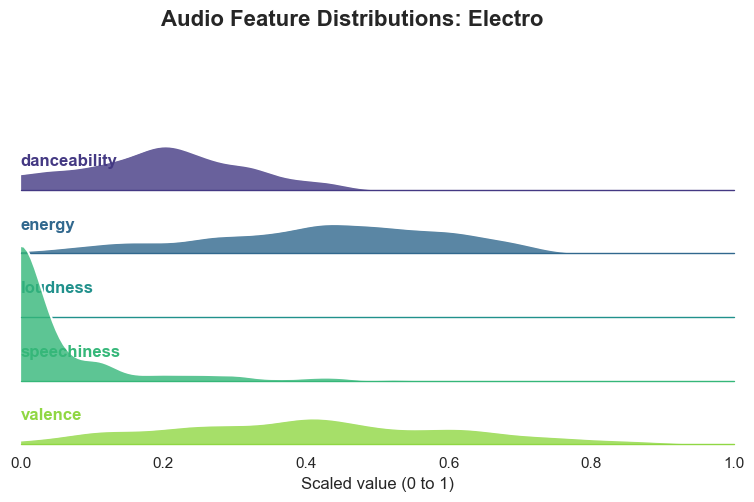

In [ ]:
sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})
palette = sns.color_palette("viridis", len(features))

g = sns.FacetGrid(long_df, row="feature", hue="feature",aspect=8, height=1.0, palette=palette)
g.map(sns.kdeplot, "value", bw_adjust=0.8, clip=(0, 1),fill=True, alpha=0.8, linewidth=0)
g.map(sns.kdeplot, "value", bw_adjust=0.8, clip=(0, 1),color="white", linewidth=1.5)
g.refline(y=0, linewidth=1, linestyle="-", color=None, clip_on=False)
def label(x, color, label):
    ax = plt.gca()
    ax.text(0, 0.2, label, fontweight="bold", color=color,ha="left", va="center", transform=ax.transAxes)
g.map(label, "value")
g.figure.subplots_adjust(hspace=-0.55)
g.set_titles("")
g.set(yticks=[], ylabel="", xlim=(0, 1))
g.despine(bottom=True, left=True)
g.set_xlabels("Scaled value (0 to 1)", fontsize=12)
g.figure.suptitle(f"Audio Feature Distributions: {genre.title()}",fontsize=16, fontweight="bold", y=1.0)

plt.show()